 Import the libraries

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Import the dataset

In [161]:
#data file
# It is come error encoding I search to solve it so -->  Using ISO-8859-1
df = pd.read_csv(r'C:\Users\dnanmol\Documents\Downloads\DAP\stores_sales_forecasting.csv', encoding='ISO-8859-1', sep=';')

Informatiom about Dataset

In [164]:
# Top 5 Rows of The Dataset
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,06/09/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,06/09/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [166]:
# Last 5 Rows of The Dataset
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
2116,9963,CA-2015-168088,3/19/2015,3/22/2015,First Class,CM-12655,Corinna Mitchell,Home Office,United States,Houston,...,77041,Central,FUR-BO-10004218,Furniture,Bookcases,Bush Heritage Pine Collection 5-Shelf Bookcase...,383.4656,4,0.32,-67.6704
2117,9965,CA-2016-146374,12/05/2016,12/10/2016,Second Class,HE-14800,Harold Engle,Corporate,United States,Newark,...,19711,East,FUR-FU-10002671,Furniture,Furnishings,Electrix 20W Halogen Replacement Bulb for Zoom...,13.4000,1,0.00,6.4320
2118,9981,US-2015-151435,09/06/2015,09/09/2015,Second Class,SW-20455,Shaun Weien,Consumer,United States,Lafayette,...,70506,South,FUR-TA-10001039,Furniture,Tables,KI Adjustable-Height Table,85.9800,1,0.00,22.3548
2119,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
2120,9991,CA-2017-121258,2/26/2017,03/03/2017,Standard Class,DB-13060,NaN,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332


In [168]:
#To find Shape of Our Dataset (Number of Rows And Number of Columns)
df.shape

(2121, 21)

In [170]:
print("Number of Rows",df.shape[0])
print("Number of Columns",df.shape[1])

Number of Rows 2121
Number of Columns 21


In [172]:
#Information for the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         2121 non-null   int64  
 1   Order ID       2121 non-null   object 
 2   Order Date     2121 non-null   object 
 3   Ship Date      2121 non-null   object 
 4   Ship Mode      2121 non-null   object 
 5   Customer ID    2121 non-null   object 
 6   Customer Name  2119 non-null   object 
 7   Segment        2121 non-null   object 
 8   Country        2121 non-null   object 
 9   City           2121 non-null   object 
 10  State          2120 non-null   object 
 11  Postal Code    2121 non-null   int64  
 12  Region         2120 non-null   object 
 13  Product ID     2121 non-null   object 
 14  Category       2121 non-null   object 
 15  Sub-Category   2121 non-null   object 
 16  Product Name   2121 non-null   object 
 17  Sales          2121 non-null   float64
 18  Quantity

Clean the dataset

In [175]:
#Identify Missing Values
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    2
Segment          0
Country          0
City             0
State            1
Postal Code      0
Region           1
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [177]:
#change the column type
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [181]:
# Fill missing values in categorical columns with the mode
df['Region'].fillna(df['Region'].mode()[0], inplace=True)
df['State'].fillna(df['State'].mode()[0], inplace=True)
df['Customer Name'].fillna(df['Customer Name'].mode(), inplace=True)

# Display the modified DataFrame
df.tail(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
2111,9932,CA-2015-104948,11/13/2015,11/17/2015,Standard Class,KH-16510,Keith Herrera,Consumer,United States,San Bernardino,...,92404,West,FUR-BO-10004357,Furniture,Bookcases,O'Sullivan Living Dimensions 3-Shelf Bookcases,683.3320,4,0.15,-40.1960
2112,9938,CA-2016-164889,06/03/2016,06/06/2016,Second Class,CP-12340,Seth Vernon,Corporate,United States,Los Angeles,...,90049,West,FUR-TA-10001676,Furniture,Tables,Hon 61000 Series Interactive Training Tables,71.0880,2,0.20,-1.7772
2113,9939,CA-2016-169824,12/12/2016,12/17/2016,Standard Class,NS-18640,Noel Staavos,Corporate,United States,New York City,...,10009,West,FUR-FU-10004864,Furniture,Furnishings,Eldon 500 Class Desk Accessories,60.3500,5,0.00,19.9155
2114,9948,CA-2017-121559,06/01/2017,06/03/2017,Second Class,HW-14935,Helen Wasserman,Corporate,United States,Indianapolis,...,46203,Central,FUR-CH-10003746,Furniture,Chairs,Hon 4070 Series Pagoda Round Back Stacking Chairs,1925.8800,6,0.00,539.2464
2115,9956,CA-2015-141593,12/14/2015,12/16/2015,Second Class,DB-12970,Darren Budd,Corporate,United States,Los Angeles,...,90045,West,FUR-TA-10002622,Furniture,Tables,"Bush Andora Conference Table, Maple/Graphite G...",273.5680,2,0.20,10.2588
2116,9963,CA-2015-168088,3/19/2015,3/22/2015,First Class,CM-12655,Corinna Mitchell,Home Office,United States,Houston,...,77041,Central,FUR-BO-10004218,Furniture,Bookcases,Bush Heritage Pine Collection 5-Shelf Bookcase...,383.4656,4,0.32,-67.6704
2117,9965,CA-2016-146374,12/05/2016,12/10/2016,Second Class,HE-14800,Harold Engle,Corporate,United States,Newark,...,19711,East,FUR-FU-10002671,Furniture,Furnishings,Electrix 20W Halogen Replacement Bulb for Zoom...,13.4000,1,0.00,6.4320
2118,9981,US-2015-151435,09/06/2015,09/09/2015,Second Class,SW-20455,Shaun Weien,Consumer,United States,Lafayette,...,70506,South,FUR-TA-10001039,Furniture,Tables,KI Adjustable-Height Table,85.9800,1,0.00,22.3548
2119,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
2120,9991,CA-2017-121258,2/26/2017,03/03/2017,Standard Class,DB-13060,Seth Vernon,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332


In [183]:
#check is there any null value else 
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [185]:
# Identify duplicates
duplicates = df.duplicated().sum()
# Display the duplicates
duplicates

0

In [187]:
#change the Data type
# Data types before conversion
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [189]:
# Convert 'Order Date' and 'Ship Date' to datetime
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors='coerce')

# Convert 'Row ID' and 'Postal Code' to string
df['Row ID'] = df['Row ID'].astype(str)
df['Postal Code'] = df['Postal Code'].astype(str)

In [191]:
#change the Data type
# Data types After conversion
df.dtypes

Row ID                   object
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code              object
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

Standardized Text Data

Validate Data Range

In [195]:

# Expected ranges for Discount from zero to .99

Discount_range = (0, .99)         # Discount should be between 0 and .99
# Step 2: Identify invalid entries
invalid_Discount = df[(df['Discount'] < Discount_range[0]) | (df['Discount'] > Discount_range[1])]
# Step 3: Print invalid entries
print("Invalid Discount Entries:",invalid_Discount)
df_cleaned = df[(df['Discount'].between(Discount_range[0], Discount_range[1]))]
print(f"Original rows: {len(df)}, Rows after removing Cleaning: {len(df_cleaned)}")



Invalid Discount Entries: Empty DataFrame
Columns: [Row ID, Order ID, Order Date, Ship Date, Ship Mode, Customer ID, Customer Name, Segment, Country, City, State, Postal Code, Region, Product ID, Category, Sub-Category, Product Name, Sales, Quantity, Discount, Profit]
Index: []

[0 rows x 21 columns]
Original rows: 2121, Rows after removing Cleaning: 2121


**********************************************************************************************
Finsh Cleaning Now  -----> Exploratory Data Analysis 
Accurately summarizing the dataset distribution. 
--> Step 1: Summary Statistics

In [198]:
df.describe()

,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,2121,2121,2121.000000,2121.000000,2121.000000,2121.000000
mean,2016-04-30 03:54:13.748231680,2016-05-04 01:54:44.299858432,349.834887,3.785007,0.173923,8.699327
min,2014-01-06 00:00:00,2014-01-10 00:00:00,1.892000,1.000000,0.000000,-1862.312400
25%,2015-05-26 00:00:00,2015-05-31 00:00:00,47.040000,2.000000,0.000000,-12.849000
50%,2016-06-20 00:00:00,2016-06-23 00:00:00,182.220000,3.000000,0.200000,7.774800
75%,2017-05-14 00:00:00,2017-05-18 00:00:00,435.168000,5.000000,0.300000,33.726600
max,2017-12-30 00:00:00,2018-01-05 00:00:00,4416.174000,14.000000,0.700000,1013.127000
std,NaN,NaN,503.179145,2.251620,0.181547,136.049246


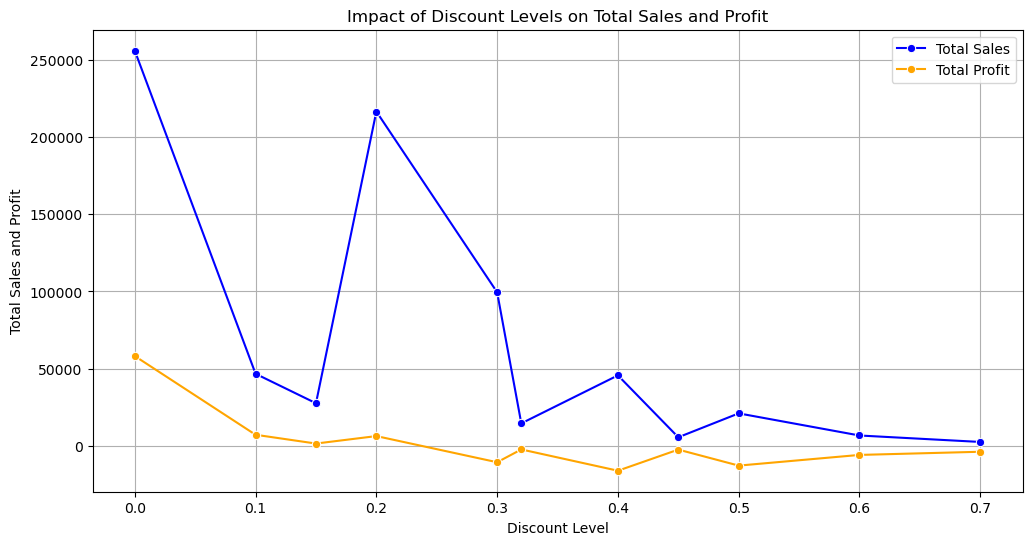

In [188]:
# 1- What is the impact of discounts on sales and profits?
summary = df.groupby('Discount').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index()
# Create a combined line plot for sales and profit
plt.figure(figsize=(12, 6))
sns.lineplot(data=summary, x='Discount', y='Sales', marker='o', label='Total Sales', color='blue')
sns.lineplot(data=summary, x='Discount', y='Profit', marker='o', label='Total Profit', color='orange')
plt.title('Impact of Discount Levels on Total Sales and Profit')
plt.xlabel('Discount Level')
plt.ylabel('Total Sales and Profit')
plt.legend()
plt.grid()
plt.show()


C:\Users\dnanmol\AppData\Local\Temp\ipykernel_6932\3347071860.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=top_states_data, x='State', y='Profit', palette='Set2')


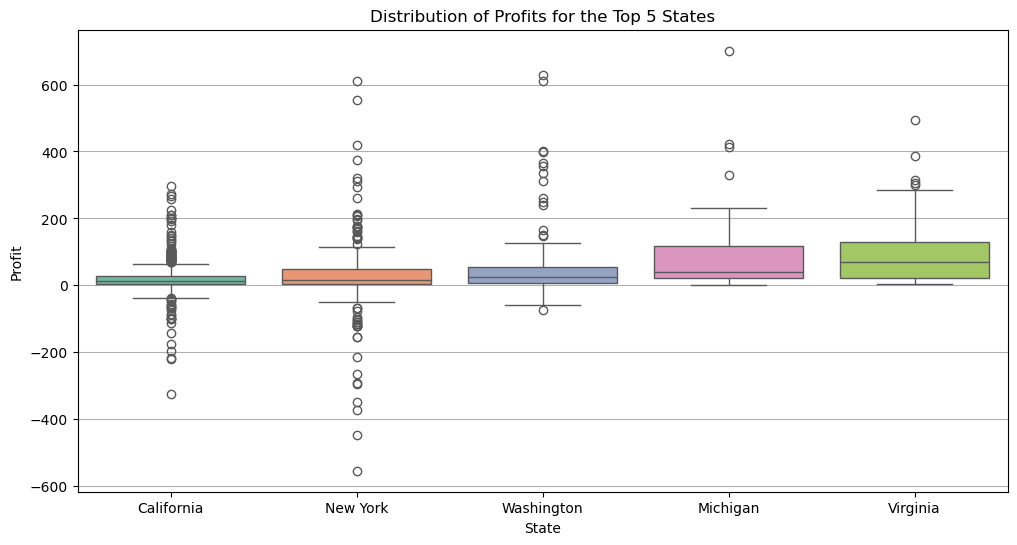

In [190]:
# 2- Distribution of Profits for Top 5 States
top_states = df.groupby('State')['Profit'].sum().nlargest(5).index
# Filter the dataset for only the top 5 states
top_states_data = df[df['State'].isin(top_states)]
# Create a box plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=top_states_data, x='State', y='Profit', palette='Set2')
plt.title('Distribution of Profits for the Top 5 States')
plt.xlabel('State')
plt.ylabel('Profit')
plt.grid(axis='y')
plt.show()

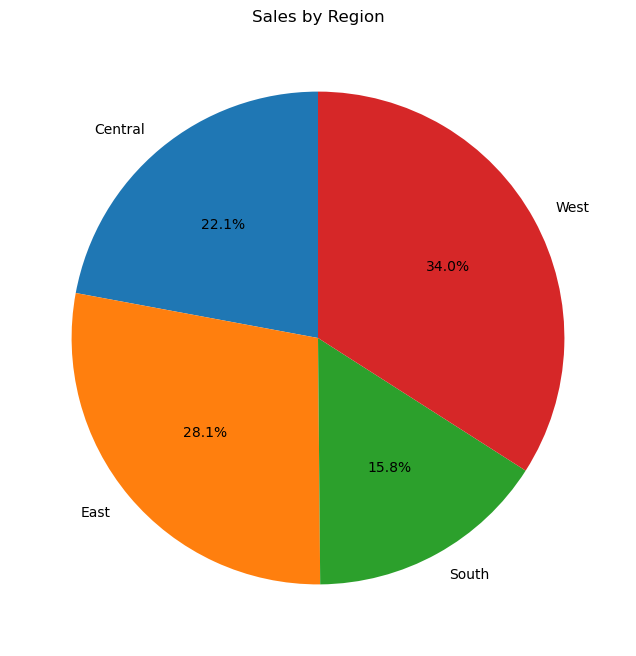

In [192]:
#3-  Which region has the most sales?
# Assuming df is your DataFrame containing the sales data
# Grouping sales by region
sales_by_region = df.groupby("Region")["Sales"].sum()
# Creating the pie chart
plt.figure(figsize=(12, 8))
sales_by_region.plot.pie(autopct='%1.1f%%', startangle=90, title="Sales by Region")
plt.ylabel('')  # Hide the y-label for clarity
plt.show()

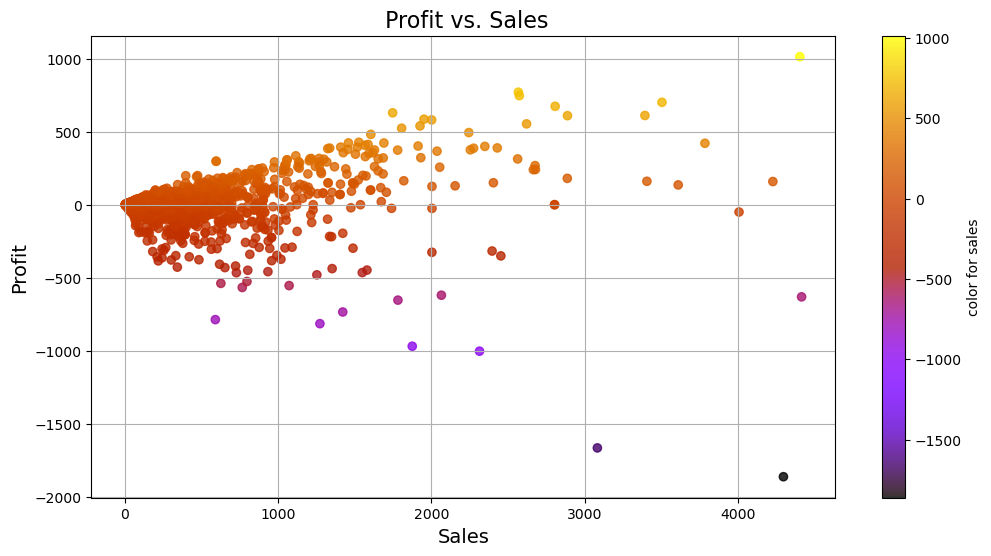

In [194]:
# 4- Create a scatter plot for 'Sales' vs. 'Profit'
plt.figure(figsize=(12, 6))
colors= df['Profit'] #--> To Make the colors darken according to the value of sales
plt.scatter(df['Sales'], df['Profit'], alpha=0.8 , c=colors, cmap='gnuplot')#--> cmap for change the color
# Add title and labels
plt.title(" Profit vs. Sales", fontsize=16)
plt.xlabel("Sales", fontsize=14)
plt.ylabel("Profit", fontsize=14)
cbar= plt.colorbar()
cbar.set_label('color for sales')
plt.grid()
plt.show()


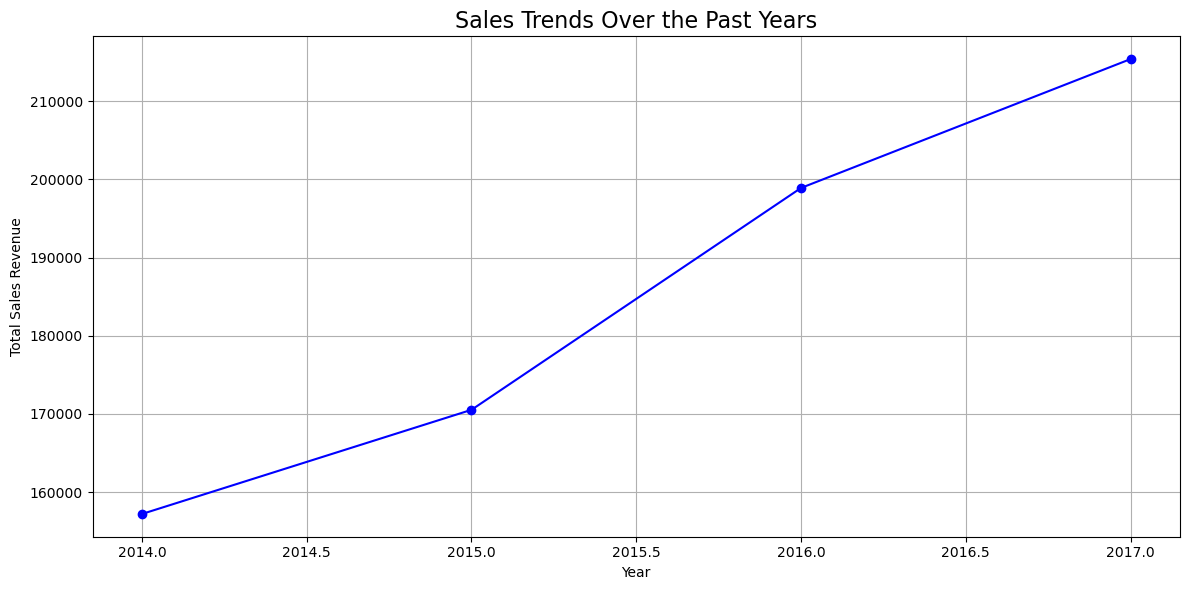

In [200]:
#5- What are the sales trends over the past years?
# Convert 'Order Date' to datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])
# Extract the year and create a new column
df['Year'] = df['Order Date'].dt.year
# Grouping sales by year
sales_trends = df.groupby('Year')['Sales'].sum().reset_index()
# Creating the line chart
plt.figure(figsize=(12, 6))
plt.plot(sales_trends['Year'], sales_trends['Sales'], marker='o', color='blue')
plt.title("Sales Trends Over the Past Years", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Total Sales Revenue")
plt.grid()
plt.tight_layout()
plt.show()


C:\Users\dnanmol\AppData\Local\Temp\ipykernel_6932\929749653.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=subcategory_sales, x='Sub-Category', y='Sales', palette='viridis', edgecolor='black')


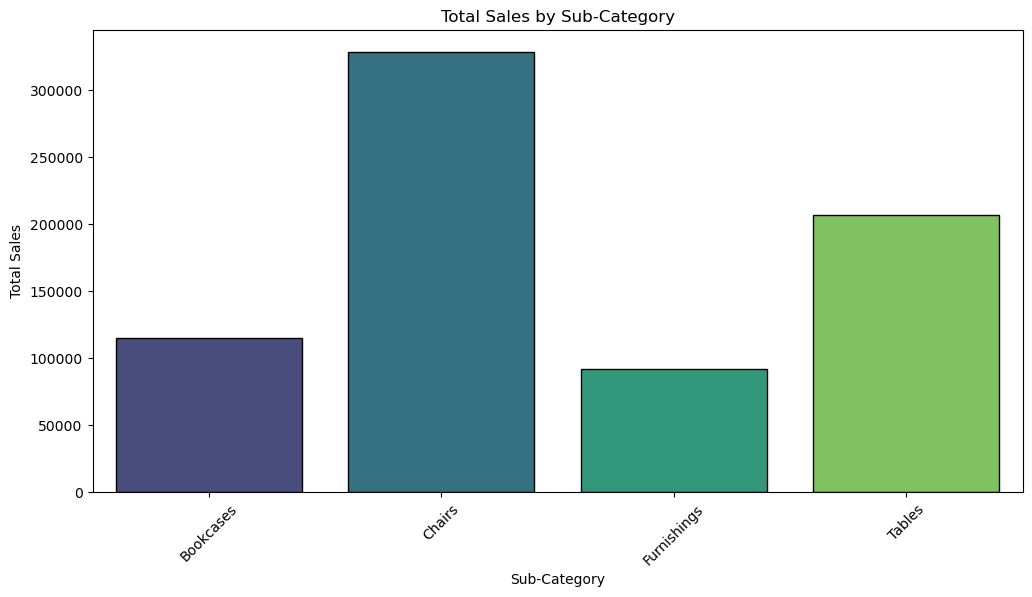

In [197]:
# 6- Which products or categories are driving growth?
# Group by 'Sub-Category' and sum the 'Sales'
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().reset_index()
# Create a bar plot for sub-category sales using Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(data=subcategory_sales, x='Sub-Category', y='Sales', palette='viridis', edgecolor='black')
plt.title("Total Sales by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)  # Rotate x labels for better readability
plt.show()


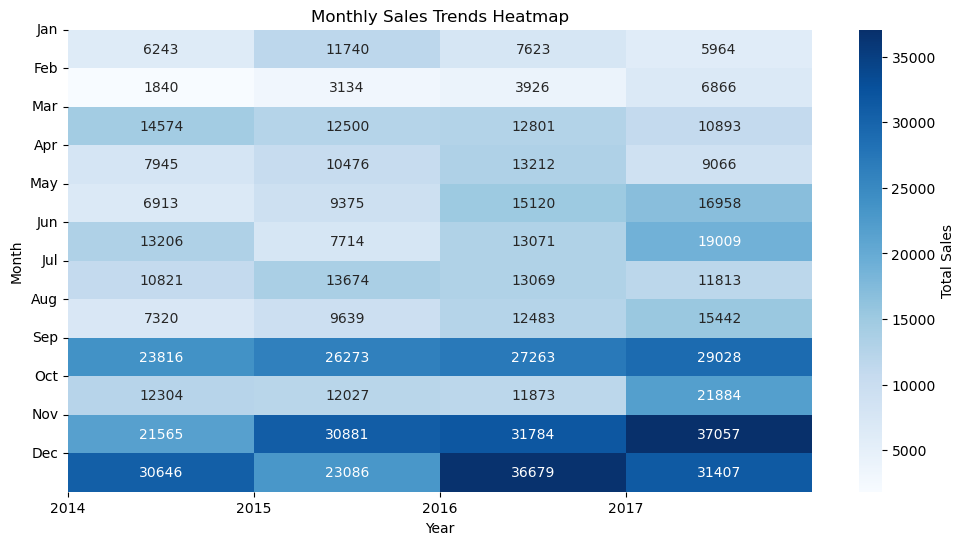

In [202]:
#  7- How do seasonal patterns affect sales?
# Convert 'Order Date' to datetime
df['Order Date'] = pd.to_datetime(df['Order Date'])
# Extract month and year
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
# Create a pivot table for sales
monthly_sales = df.pivot_table(values='Sales', index='Month', columns='Year', aggfunc='sum')
# Create a heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(monthly_sales, annot=True, fmt=".0f", cmap='Blues', cbar_kws={'label': 'Total Sales'})
plt.title('Monthly Sales Trends Heatmap')
plt.xlabel('Year')
plt.ylabel('Month')
plt.xticks(ticks=range(len(monthly_sales.columns)), labels=monthly_sales.columns)
plt.yticks(ticks=range(len(monthly_sales.index)), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=0)
plt.show()

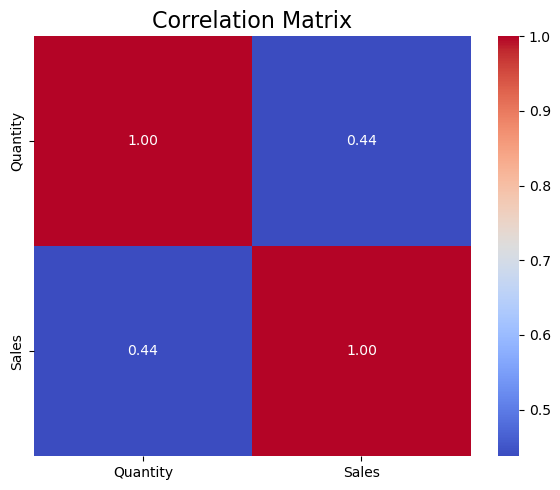

In [201]:
# 8- How does the quantity sell correlate with the total sales revenue? Does selling more units typically result in higher sales?
# Set the figure size
plt.figure(figsize=(6, 5))
# Calculate the correlation
correlation = df[['Quantity', 'Sales']].corr()
# Create a heatmap for the correlation matrix
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
# Add title
plt.title("Correlation Matrix", fontsize=16)
plt.tight_layout()  # Adjust layout for better fit
plt.show()

C:\Users\dnanmol\AppData\Local\Temp\ipykernel_6932\1832344130.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_by_segment, x='Segment', y='Sales', palette='viridis')


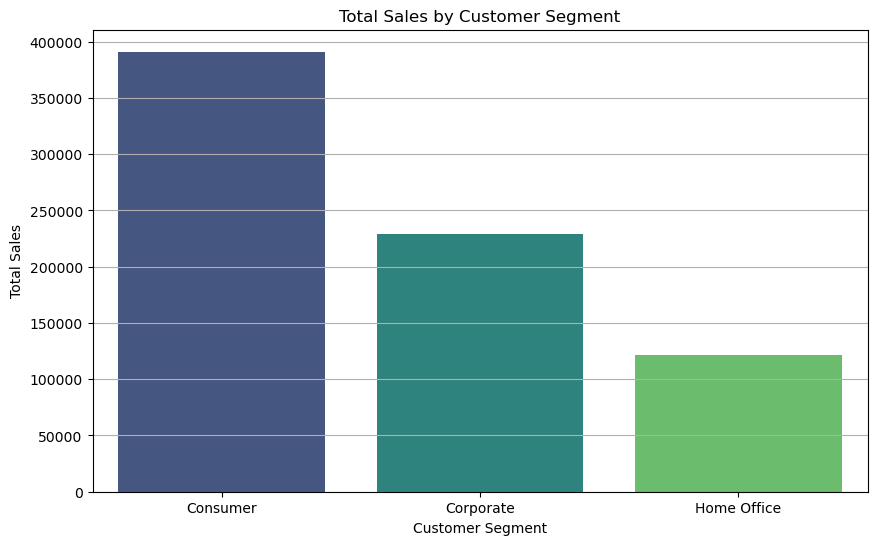

In [204]:
# 9- How do sales figures correlate with different customer segments (e.g., Consumer, Corporate, Home Office)?
sales_by_segment = df.groupby('Segment')['Sales'].sum().reset_index()
# Create a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(data=sales_by_segment, x='Segment', y='Sales', palette='viridis')
plt.title('Total Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.grid(axis='y')
plt.show()

Select numerical features

In [223]:
# Select only numerical columns
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
df = df.select_dtypes(include=numerics)
df.head()

,Sales,Quantity,Discount,Profit,Year,Month
0,261.9600,2,0.00,41.9136,2016,11
1,731.9400,3,0.00,219.5820,2016,11
2,957.5775,5,0.45,-383.0310,2015,10
3,48.8600,7,0.00,14.1694,2014,6
4,1706.1840,9,0.20,85.3092,2014,6


 Split the dataset into the Training set and Test set 

In [210]:
# Split train -> train, validation
from sklearn.model_selection import train_test_split
X = df[df.columns.drop(['Sales'])]
y = df[ ['Sales' ] ]
X_train, X_val, y_train, y_val=train_test_split(X, y, test_size=0.33, random_state=42)

In [212]:
print("Original train shape:", X.shape)
print()

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print()

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

Original train shape: (2121, 5)

X_train shape: (1421, 5)
X_val shape: (700, 5)

y_train shape: (1421, 1)
y_val shape: (700, 1)


Create a Regression model using the Training set

In [214]:
# Fit Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

Predict the Test set results

In [216]:
# Predict the Test set results
y_pred = model.predict(X_val)
y_pred

array([[ 429.80154244],
       [ 698.40504149],
       [ 232.33959192],
       [ 850.13502613],
       [ 199.0038123 ],
       [ 771.77709107],
       [ 442.64971544],
       [ 651.04143688],
       [ 644.4536584 ],
       [ 623.67852776],
       [ 238.5823807 ],
       [ 162.93187018],
       [ 261.56858519],
       [  72.72849484],
       [ 214.55622882],
       [ 165.97768049],
       [ 170.33761121],
       [  85.52360289],
       [ 176.00382267],
       [ 251.70067411],
       [ 307.31202698],
       [ 405.60081073],
       [ 560.15916908],
       [ 187.49753155],
       [ 182.77810598],
       [ 805.957194  ],
       [ 217.38606052],
       [ 299.47538471],
       [ 437.98694078],
       [  74.78743205],
       [ 263.0560353 ],
       [ 618.6412987 ],
       [ 663.58452771],
       [ 571.89824024],
       [ 735.82438996],
       [ 199.683692  ],
       [ 286.41627036],
       [ 300.21519842],
       [ 289.9413507 ],
       [ 354.48061388],
       [ 351.37208733],
       [ 270.719

Performance Evaluation

In [235]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
print('MSE = ',mean_squared_error(y_val,y_pred))
print('RMSE = ',np.sqrt(mean_squared_error(y_val,y_pred)))
print('MAE = ', mean_absolute_error(y_val,y_pred))
print('R2 score = ',r2_score(y_val,y_pred))

MSE =  207398.44605573663
RMSE =  455.4101953796562
MAE =  287.0711534922303
R2 score =  0.21278671179436626


In [204]:
df['Region'].unique()

array(['South', 'West', 'East', 'Central'], dtype=object)

In [206]:
df['Region']=df['Region'].map({'South':0,'West':1,'East':2,'Central':3})

In [208]:
df['Segment'].unique()

array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

In [210]:
df['Segment']=df['Segment'].map({'Consumer':0,'Corporate':1,'Home Office':2})

In [212]:
df['Country'].unique()

array(['United States'], dtype=object)

In [214]:
df['Country']=df['Country'].map({'United States':0})

In [216]:
df['Ship Mode'].unique()

array(['Second Class', 'Standard Class', 'First Class', 'Same Day'],
      dtype=object)

In [218]:
df['Ship Mode']=df['Ship Mode'].map({'Second Class':0,'Standard Class':1,'First Class':2,'Same Day':3})

In [220]:
df['Category'].unique()

array(['Furniture'], dtype=object)

In [222]:
df['Category']=df['Category'].map({'Furniture':0})

In [224]:
df['Sub-Category'].unique()

array(['Bookcases', 'Chairs', 'Tables', 'Furnishings'], dtype=object)

In [226]:
df['Sub-Category']=df['Sub-Category'].map({'Bookcases':0,'Chairs':1,'Tables':2,'Furnishings':3})

In [238]:
# Select only numerical columns
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
numerical_features = df.select_dtypes(include=numerics)
numerical_features.head()

,Ship Mode,Segment,Country,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit,Year,Month
0,0,0,0,0,0,0,261.9600,2,0.00,41.9136,2016,11
1,0,0,0,0,0,1,731.9400,3,0.00,219.5820,2016,11
2,1,0,0,0,0,2,957.5775,5,0.45,-383.0310,2015,10
3,1,0,0,1,0,3,48.8600,7,0.00,14.1694,2014,6
4,1,0,0,1,0,2,1706.1840,9,0.20,85.3092,2014,6


In [252]:
# Split train -> train, validation
from sklearn.model_selection import train_test_split
X = numerical_features.drop('Sales', axis=1)  
y = numerical_features['Sales']
X_train, X_val, y_train, y_val=train_test_split(X, y, test_size=0.33, random_state=42)

In [254]:
# Fit Linear Regression Model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [256]:
# Predict the Test set results
y_pred = model.predict(X_val)
y_pred

array([ 2.64408566e+02,  6.72341784e+02,  8.29681078e+01,  6.53843007e+02,
       -1.90647749e+01,  6.21309796e+02,  2.72927949e+02,  4.90780740e+02,
        4.73409497e+02,  4.53209291e+02,  3.73071673e+02,  2.64917648e+01,
        2.36958108e+02, -8.54715640e+01,  3.42456921e+02,  1.77743111e+01,
        1.93028051e+01,  2.45638991e+02,  2.67226601e+01,  8.93266184e+01,
        1.24962443e+02,  5.28994968e+02,  3.13280835e+02,  3.70352319e+02,
        3.12016608e+02,  9.81058225e+02,  8.07263211e+01,  1.46787440e+02,
        6.17884778e+02, -1.71286444e+02,  1.08984761e+02,  4.40000318e+02,
        4.85948468e+02,  6.96824107e+02,  5.68186596e+02,  3.32388905e+02,
        1.05681103e+02,  4.57283297e+02,  4.34976006e+02,  1.83985748e+02,
        3.18232901e+02,  1.02173405e+02,  7.33237526e+02, -9.06396323e+01,
        1.22751384e+03,  4.77756578e+02,  5.97704492e+02,  9.39882844e+01,
        2.55966115e+01,  4.26135422e+02,  3.92048797e+01, -6.31238214e+01,
        8.23506623e+01, -

In [258]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
print('MSE = ',mean_squared_error(y_val,y_pred))
print('RMSE = ',np.sqrt(mean_squared_error(y_val,y_pred)))
print('MAE = ', mean_absolute_error(y_val,y_pred))
print('R2 score = ',r2_score(y_val,y_pred))

MSE =  178319.67040906622
RMSE =  422.27913802254807
MAE =  255.8749424832864
R2 score =  0.3231597595637671


End Of analysis